# 05 · Long-term reservoir simulation

$$V(t+1) = V(t) + Q_{in} - Q_e - E - Q_s - Q_{spill}, \qquad V_{min} \le V \le V_{max}$$

Each month: (1) add the inflow, (2) release the e-flow $Q_e = \min(Q_{e,target}, Q_{in})$ with
$Q_{e,target}(m) = 0.10 \cdot \overline{Q_{in}}(m)$, (3) evaporation $E = PET \cdot A / 1000$ (hm³, never
below $V_{min}$), (4) supply $Q_s = \min(D, V - V_{min})$, (5) spill above $V_{max}$. Start full.

First with a fixed area $A_0$, then with $A(h) = dV/dh$ from the h–V curve.

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, "../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = Path("../data")
PROC = DATA / "processed"
PROC.mkdir(exist_ok=True)
case = json.loads((DATA / "case.json").read_text())
case

{'catchment_area_km2': 55.33,
 'latitude_deg': 38.237,
 'longitude_deg': -7.687,
 'smax_mm': 100,
 'hmax_m': 5.0,
 'hmin_m': 1.0,
 'area_fixed_km2': 0.0685,
 'irrigation_months': [6, 7, 8, 9],
 'demand_hm3_per_month': 0.02,
 'eflow_fraction': 0.1,
 'target_reliability': 0.9}

In [2]:
from epss.eflows import eflow_targets
from epss.reservoir import Reservoir

cat = pd.read_csv(PROC / "catchment.csv", index_col=0, parse_dates=True)
inflow, evap = cat.inflow, cat.pet
hv = pd.read_csv(DATA / "hv_curve.csv")

Demand: $D$ in the irrigation months, 0 otherwise. E-flow targets by calendar month.

In [3]:
# TODO: Demand series: case['demand_hm3_per_month'] in the irrigation months
#       (case['irrigation_months']), 0 otherwise.
# In: inflow.index, case
# Out: demand (pd.Series, hm³/month)
demand = pd.Series(
    np.where(inflow.index.month.isin(case["irrigation_months"]), case["demand_hm3_per_month"], 0.0),
    index=inflow.index, name="demand")


eflow = eflow_targets(inflow, case["eflow_fraction"])
pd.DataFrame({"inflow": inflow, "eflow target": eflow, "demand": demand}).groupby(inflow.index.month).mean().round(4)

,inflow,eflow target,demand
1,1.0071,0.1007,0.00
2,0.6179,0.0618,0.00
3,0.3641,0.0364,0.00
4,0.0729,0.0073,0.00
5,0.0000,0.0000,0.00
6,0.0000,0.0000,0.02
7,0.0000,0.0000,0.02
8,0.0000,0.0000,0.02
9,0.0000,0.0000,0.02
10,0.0000,0.0000,0.00


## h–V and h–A curves

Vmax = 0.252 hm³, Vmin = 0.0045 hm³


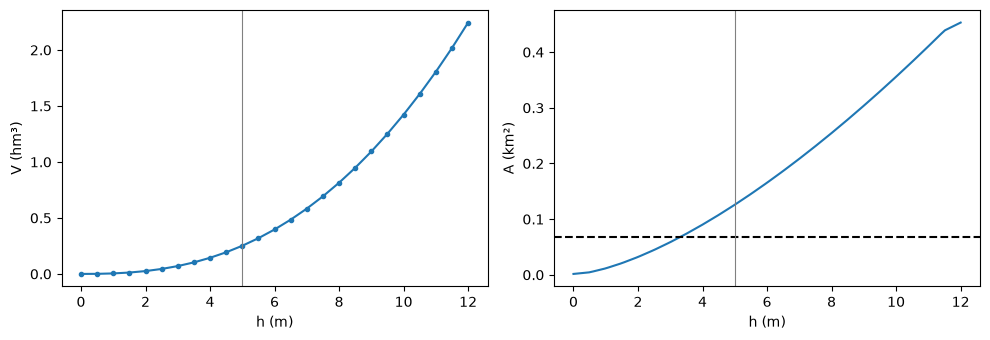

In [4]:
res_var = Reservoir(hv, case["hmax_m"], case["hmin_m"])
h = np.linspace(0, hv.h_m.max(), 100)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(hv.h_m, hv.v_hm3, "o-", ms=3); ax[0].set_xlabel("h (m)"); ax[0].set_ylabel("V (hm³)")
ax[1].plot(h, [res_var.area(res_var.volume(x)) for x in h]); ax[1].axhline(case["area_fixed_km2"], ls="--", c="k")
ax[1].set_xlabel("h (m)"); ax[1].set_ylabel("A (km²)")
for a in ax: a.axvline(case["hmax_m"], c="grey", lw=0.8)
plt.tight_layout()
print(f"Vmax = {res_var.vmax:.3f} hm³, Vmin = {res_var.vmin:.4f} hm³")

## Fixed surface area $A_0$

In [5]:
res_fix = Reservoir(hv, case["hmax_m"], case["hmin_m"], area=case["area_fixed_km2"])
sim_fix = res_fix.simulate(inflow, evap, demand, eflow)
sim_fix.head(12).round(4)

,inflow,eflow,evaporation,supply,deficit,spill,volume,level
1981-01-01,0.0000,0.0000,0.0030,0.00,0.0,0.0000,0.2486,4.9745
1981-02-01,0.0000,0.0000,0.0035,0.00,0.0,0.0000,0.2451,4.9445
1981-03-01,0.0000,0.0000,0.0055,0.00,0.0,0.0000,0.2395,4.8969
1981-04-01,0.0000,0.0000,0.0061,0.00,0.0,0.0000,0.2334,4.8444
1981-05-01,0.0000,0.0000,0.0088,0.00,0.0,0.0000,0.2246,4.7689
1981-06-01,0.0000,0.0000,0.0124,0.02,0.0,0.0000,0.1923,4.4895
1981-07-01,0.0000,0.0000,0.0136,0.02,0.0,0.0000,0.1587,4.1488
1981-08-01,0.0000,0.0000,0.0117,0.02,0.0,0.0000,0.1270,3.7922
1981-09-01,0.0000,0.0000,0.0080,0.02,0.0,0.0000,0.0990,3.4375
1981-10-01,0.0000,0.0000,0.0055,0.00,0.0,0.0000,0.0936,3.3549


Conservation of mass over the whole simulation: $V_{end} - V_0 = \sum(Q_{in} - Q_e - E - Q_s - Q_{spill})$.

In [6]:
# TODO: Mass balance over the whole simulation: (V_end - V0) - sum(Qin - Qe - E - Qs - Qspill),
#       with V0 = Vmax.
# In: sim_fix, res_fix.vmax
# Out: out (hm³, sum of all outflows), error (hm³)
out = (sim_fix.eflow + sim_fix.evaporation + sim_fix.supply + sim_fix.spill).sum()   # all outflows
error = (sim_fix.volume.iloc[-1] - res_fix.vmax) - (sim_fix.inflow.sum() - out)
print(f"Mass balance error: {error:.2e} hm³")
sim_fix[["inflow", "eflow", "evaporation", "supply", "spill", "deficit"]].sum().round(3)

Mass balance error: 4.72e-15 hm³


inflow         163.179
eflow            5.361
evaporation      2.672
supply           2.451
spill          152.944
deficit          0.749
dtype: float64

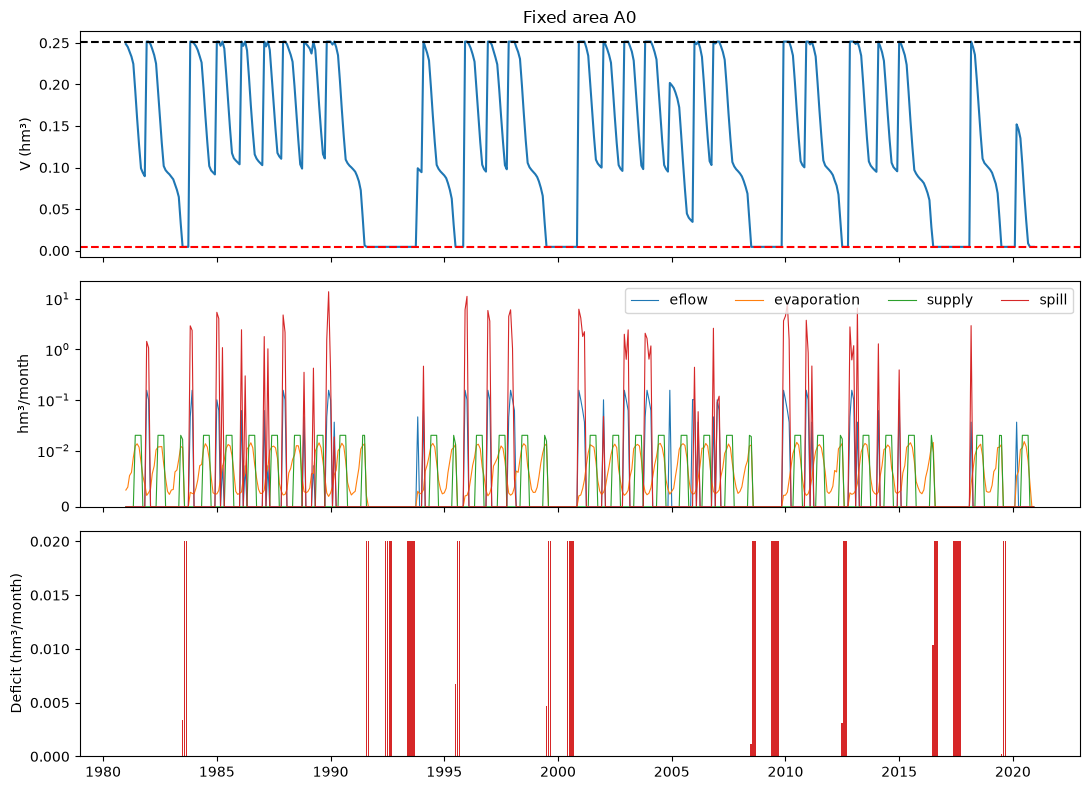

In [7]:
def plot_sim(sim, res, title):
    fig, ax = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
    ax[0].plot(sim.index, sim.volume); ax[0].axhline(res.vmax, c="k", ls="--"); ax[0].axhline(res.vmin, c="r", ls="--")
    ax[0].set_ylabel("V (hm³)"); ax[0].set_title(title)
    for col in ["eflow", "evaporation", "supply", "spill"]:
        ax[1].plot(sim.index, sim[col], lw=0.8, label=col)
    ax[1].set_yscale("symlog", linthresh=0.01); ax[1].set_ylim(0, None)
    ax[1].set_ylabel("hm³/month"); ax[1].legend(ncol=4)
    ax[2].bar(sim.index, sim.deficit, width=25, color="tab:red"); ax[2].set_ylabel("Deficit (hm³/month)")
    plt.tight_layout()

plot_sim(sim_fix, res_fix, "Fixed area A0")

In [8]:
# TODO: Critical periods: months with deficit, grouped by year, with their count and total
#       deficit.
# In: sim_fix
# Out: fail (rows with deficit > 0), critical (DataFrame by year with columns count, sum)
fail = sim_fix[sim_fix.deficit > 1e-12]                              # months with a deficit
critical = fail.groupby(fail.index.year)["deficit"].agg(["count", "sum"])
critical.index.name = "year"
critical.rename(columns={"count": "months with deficit", "sum": "deficit (hm³)"}).round(3)

,months with deficit,deficit (hm³)
year,,
1983,3,0.043
1991,2,0.040
1992,4,0.080
1993,4,0.080
1995,3,0.047
1999,3,0.045
2000,4,0.080
2008,3,0.041
2009,4,0.080


## Surface area from the h–V curve, $A(h) = dV/dh$

,fixed A0,A(h)
evaporation,2.672,3.416
supply,2.451,2.362
deficit,0.749,0.838
spill,152.944,152.285
mean level (m),3.427,3.196


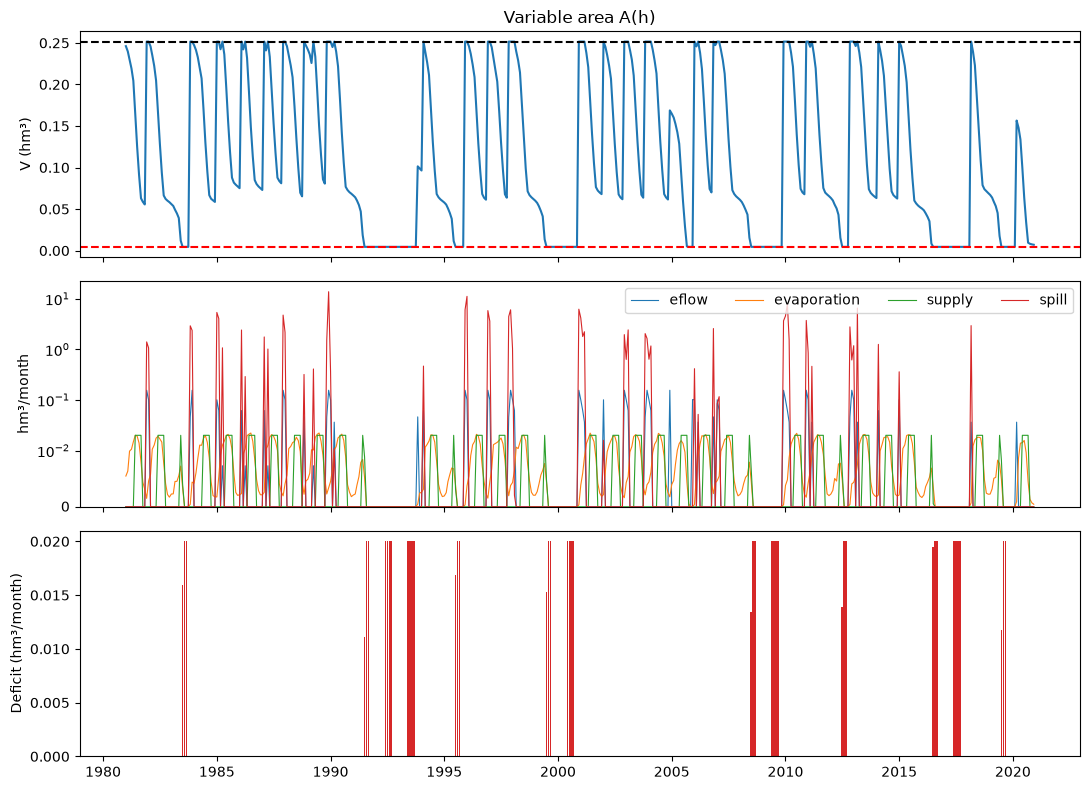

In [9]:
sim_var = res_var.simulate(inflow, evap, demand, eflow)
plot_sim(sim_var, res_var, "Variable area A(h)")
compare = pd.DataFrame({"fixed A0": sim_fix[["evaporation", "supply", "deficit", "spill"]].sum(),
                        "A(h)": sim_var[["evaporation", "supply", "deficit", "spill"]].sum()})
compare.loc["mean level (m)"] = [sim_fix.level.mean(), sim_var.level.mean()]
compare.round(3)

**Answer.**

*Your answer here.*